# Weighted split conformal

[Split conformal](split) treats every calibration residual as equally
informative about the next one. That is exactly what exchangeability buys, and
**covariate shift** is the assumption failing in the most common way: the steps
you are about to predict do not look like the steps you calibrated on. A model
calibrated on a quiet, low-volume stretch of a series is asked about a high-volume
one; a panel calibrated on one set of stores is asked about another.

`WeightedSplit` keeps the whole split-conformal construction and changes exactly
one thing: each calibration score gets a **weight** saying how likely its
features are under the target distribution rather than the source one. Nothing
about the forecaster changes, and no target labels are needed.

## What it does

Write `x` for the features of a predicted step. The importance weight is the
density ratio

```
w(x) = d_target(x) / d_source(x)
```

Calibration scores `s_1 ... s_n` are then normalized *including the test point's
own weight*, and the interval takes the smallest score whose cumulative
normalized weight reaches `1 - alpha`:

```
p_i = w(x_i) / (sum_j w(x_j) + w(x_test))
q   = min { s_i : sum_{s_k <= s_i} p_k >= 1 - alpha }
```

The interval is `[y_hat - q, y_hat + q]`, one `q` per `(series, sample, horizon)`
cell — the quantile now moves with the test point, which the unweighted method's
does not. Set every `w` to 1 and the `w(x_test)` term becomes the familiar `+1`
of `k = ceil((1 - alpha)(n + 1))`, recovering split conformal exactly. That is
not a metaphor: before `adapt()` binds a weight function, `WeightedSplit` is
bit-identical to `SplitConformal`, and a test asserts it.

The ratio itself is estimated, not known. `DensityRatio` labels source rows `0`
and target rows `1`, fits any binary classifier you hand it, and reads the ratio
off the odds `p / (1 - p)`. Calibration weights are computed **out of fold**, so
a calibration point's weight never comes from a model that trained on it.


## Worked example

AirPassengers has one property that makes it a clean covariate-shift test: its
error scale grows with its level. So `log` of the last twelve months' mean is a
real driver of how large the next residual will be — a genuine covariate, not a
label in disguise.

The shift is built by splitting one-step-ahead windows on that feature: each
window goes to calibration or holdout with a probability that rises with its
level. Both halves keep full support — high-level windows appear in calibration
too, just rarely — which is the regime weighted conformal is built for, and the
regime it needs. A source that never saw the target's features cannot be
reweighted into it.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression

from conformalforecast import WeightedSplit
from conformalforecast.adapters import CallableAdapter
from conformalforecast.weighting import DensityRatio

HORIZON, SEASON, ALPHA = 1, 12, 0.1

df = pd.read_csv("nbs/data/air_passengers.csv", parse_dates=["ds"])
series = df["y"].to_numpy()
T = series.size


def seasonal_naive(history):
    """Repeat the value from one season ago. Instant, and good enough here."""
    return history[:, -SEASON : -SEASON + HORIZON]


forecaster = CallableAdapter(predict_fn=seasonal_naive, horizon=HORIZON, n_series=1)

# One window per forecastable timestamp; its feature is known before the truth is.
starts = np.arange(2 * SEASON, T - HORIZON + 1)
levels = np.array([np.log(series[t - SEASON : t].mean()) for t in starts])

rng = np.random.default_rng(0)
z = (levels - np.median(levels)) / levels.std()
is_target = rng.random(starts.size) < 1 / (1 + np.exp(-3 * z))

print(f"{(~is_target).sum()} calibration windows, {is_target.sum()} holdout windows")
print(
    f"mean log-level: source {levels[~is_target].mean():.2f}, target {levels[is_target].mean():.2f}"
)

65 calibration windows, 55 holdout windows
mean log-level: source 5.40, target 5.88


The two halves are the same series, the same forecaster and the same horizon.
Only the feature distribution differs — which is the definition of covariate
shift, and the only thing weighting can repair.


In [ ]:
def build(mask):
    """Histories, truths and the 4-D feature block for a set of windows."""
    idx = np.flatnonzero(mask)
    histories = [series[None, :t] for t in starts[idx]]
    truths = np.stack([series[None, t : t + HORIZON] for t in starts[idx]], axis=1)
    X = np.stack([np.full((1, HORIZON, 1), levels[i]) for i in idx], axis=1)
    return histories, truths, X


src_histories, src_truths, src_X = build(~is_target)
tgt_histories, tgt_truths, tgt_X = build(is_target)

print("truths    ", src_truths.shape, "(n_series, n_windows, horizon)")
print("X         ", src_X.shape, "(n_series, n_windows, horizon, n_features)")

truths     (1, 65, 1) (n_series, n_windows, horizon)
X          (1, 65, 1, 1) (n_series, n_windows, horizon, n_features)


## Calibrate, then adapt

`calibrate(forecaster, histories, truths)` is the ordinary source-domain verb: it
fits the conformal quantile on source forecasts and source truths.
`adapt(weighting=..., target_X=...)` is the transfer verb, called on the fitted
object `calibrate` returned: it hands a weight function the **features** of the
target domain — no target truths — and returns a new fitted object with the
quantile rebuilt, leaving the source fit untouched. See [Transfer and adaptation](../capabilities/transfer) for the
full set of verbs.


In [ ]:
def holdout_intervals(fitted, X=None):
    """Predict every holdout window, returning (n_windows, horizon) bounds."""
    lower, upper = [], []
    for k, history in enumerate(tgt_histories):
        step_X = None if X is None else X[:, k : k + 1]
        prediction = fitted.predict(history, X=step_X)
        lower.append(prediction.interval[0, 0, :, 0])
        upper.append(prediction.interval[0, 0, :, 1])
    return np.array(lower), np.array(upper)


def report(name, lower, upper):
    truth = tgt_truths[0]
    covered = ((truth >= lower) & (truth <= upper)).mean()
    print(f"{name:22s} coverage {covered:6.1%}   mean width {(upper - lower).mean():6.1f}")
    return covered


uniform = WeightedSplit(alpha=ALPHA).calibrate(forecaster, src_histories, src_truths, X=src_X)
uniform_bounds = holdout_intervals(uniform)

source = WeightedSplit(alpha=ALPHA).calibrate(forecaster, src_histories, src_truths, X=src_X)
weighted = source.adapt(
    weighting=DensityRatio(estimator=LogisticRegression(max_iter=1000), cv=5),
    target_X=tgt_X,
)
weighted_bounds = holdout_intervals(weighted, tgt_X)

report("uniform weights", *uniform_bounds)
report("density-ratio weights", *weighted_bounds)
summary = weighted.calibration_.diagnostics["weight_summary"]
print("weight summary        ", {k: round(v, 3) for k, v in summary.items()})

uniform weights        coverage  78.2%   mean width  104.0
density-ratio weights  coverage  89.1%   mean width  116.3
weight summary         {'min': 0.012, 'median': 0.181, 'max': 5.129}


Uniform weights under-cover: 78.2% against a 90% target, at a mean width of 104.0. The calibration set is dominated by low-level windows whose residuals are small, so the band is too narrow for the high-level windows it is asked about. Density-ratio weights push mass onto the calibration windows that resemble the target, and coverage climbs to 89.1% — a shade under nominal, well within what 65 calibration windows can resolve — at a mean width of 116.3. That trade is the whole method: the extra width is not waste, it is the width the target regime always needed.


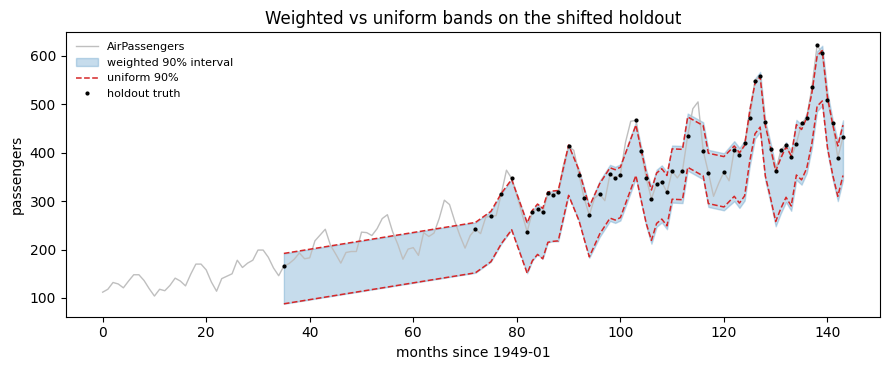

In [ ]:
order = np.argsort(starts[is_target])
t_axis = starts[is_target][order]
truth = tgt_truths[0, order, 0]

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(np.arange(T), series, color="0.75", lw=1, label="AirPassengers")
ax.fill_between(
    t_axis,
    weighted_bounds[0][order, 0],
    weighted_bounds[1][order, 0],
    color="C0",
    alpha=0.25,
    label="weighted 90% interval",
)
ax.plot(t_axis, uniform_bounds[0][order, 0], color="C3", lw=1.1, ls="--", label="uniform 90%")
ax.plot(t_axis, uniform_bounds[1][order, 0], color="C3", lw=1.1, ls="--")
ax.plot(t_axis, truth, "k.", ms=4, label="holdout truth")
ax.set_xlabel("months since 1949-01")
ax.set_ylabel("passengers")
ax.set_title("Weighted vs uniform bands on the shifted holdout")
ax.legend(loc="upper left", fontsize=8, frameon=False)
fig.tight_layout()

## Clipping, and how it can cost you coverage

An estimated density ratio is unbounded. One calibration point whose classifier
odds come out at 300 can carry more weight than the rest of the panel put
together, and the weighted quantile then rests on a single residual.
`DensityRatio` guards against that by clipping weights at their
`clip_quantile`, default `0.99`.

The guard is not free. Under a strong shift the *typical* target weight is
already large, so a clip calibrated on the source weights binds on most of the
test points — and every clipped point is one whose weighting signal was thrown
away. The sweep below is the synthetic covariate-shift benchmark this package
tests against: feature-dependent noise, calibration drawn at `loc=0` and test at
`loc=2.5`, 90% target.


In [ ]:
def shifted(n, seed, loc):
    """Zero forecasts with noise whose scale grows with a single feature."""
    gen = np.random.default_rng(seed)
    x = gen.normal(loc=loc, scale=1.0, size=(1, n, 1))
    noise = gen.normal(scale=1.0 + np.abs(x), size=(1, n, 1))
    return np.zeros((1, n, 1)), noise, x[..., np.newaxis]


cal_p, cal_t, cal_X = shifted(2000, 0, loc=0.0)
test_p, test_t, test_X = shifted(4000, 1, loc=2.5)


def sweep_coverage(fitted):
    iv = fitted.interval(test_p, X=test_X)
    return float(((test_t >= iv[..., 0]) & (test_t <= iv[..., 1])).mean())


plain = WeightedSplit(alpha=ALPHA).fit(cal_p, cal_t, X=cal_X)
print(f"uniform weights          coverage {sweep_coverage(plain):.4f}")

for clip in (None, 0.99, 0.999):
    adapted = plain.adapt(
        weighting=DensityRatio(
            estimator=LogisticRegression(max_iter=1000), cv=3, clip_quantile=clip
        ),
        target_X=test_X,
    )
    label = "off" if clip is None else str(clip)
    print(f"density ratio, clip {label:5s} coverage {sweep_coverage(adapted):.4f}")

uniform weights          coverage 0.6520
density ratio, clip off   coverage 0.9167
density ratio, clip 0.99  coverage 0.8213
density ratio, clip 0.999 coverage 0.8692


Read that table before accepting the default. Weighting is doing its job — with clipping off, coverage goes from 0.6520 to 0.9167 against a 0.90 target. But at the default `clip_quantile=0.99` the same weights deliver only 0.8213, because under this much shift the *median* test weight saturates at the clip value: the guard binds on 59% of the points and discards most of the signal it was meant to protect. Loosening it to `0.999` recovers part of the gap, at 0.8692.

::: {.callout-warning}
## Tune `clip_quantile` against measured coverage

`clip_quantile=0.99` is a safe default for a mild shift and a poor one for a
strong shift. If your weights are large across the board, the clip is not
trimming outliers — it is flattening the whole weighting. Check the
adapted object's `calibration_.diagnostics["weight_summary"]`: when the median sits at the maximum,
the clip is binding everywhere.
:::


## When not to use it

- **The shift is in `P(y|x)`, not `P(x)`.** Weighting reweights calibration
  points by how *likely their features* are in the target domain. It assumes the
  conditional error distribution given those features is unchanged. If the
  relationship itself moved — a new pricing rule, a changed measurement process,
  a forecaster that has gone stale — no reweighting of the old residuals
  describes the new ones. That is a job for
  [recalibration on target labels](../capabilities/transfer) if you have them,
  or an [online method](aci) if you do not.
- **The density ratio is badly estimated.** The weights are the output of a
  classifier, and a bad classifier gives confidently wrong weights. Too flexible
  and it memorises which rows are source and which are target, sending the ratio
  to zero and infinity; too rigid and it returns a constant, which is uniform
  weighting under another name. Clipping bounds the damage without removing it —
  and as the sweep above shows, the clip has its own failure mode.
- **The supports do not overlap.** If no calibration window looks anything like
  the target, `d_source(x)` is near zero where the target lives, and the ratio is
  an extrapolation dressed up as a weight. Weighting redistributes evidence; it
  cannot manufacture it.
- **You have target labels.** If you can observe target `(prediction, truth)`
  pairs, calibrating on them directly is strictly better than reweighting a
  proxy. Use [`recalibrate()`](../capabilities/transfer).
- **You have no features at all.** With `X=None` the weight function cannot fit
  and `WeightedSplit` is plain split conformal. Reach for
  [NexCP](nexcp) instead, which down-weights by *recency* rather than by
  features and needs no covariates.

## References
- R. J. Tibshirani, R. F. Barber, E. J. Candes, and A. Ramdas, "Conformal
  prediction under covariate shift," *Advances in Neural Information Processing
  Systems 32*, 2019. https://arxiv.org/abs/1904.06019

## Next

- [Transfer and adaptation](../capabilities/transfer) — `calibrate`,
  `recalibrate` and `adapt`, and which one your target data allows.
- [Split conformal](split) — the unweighted method this reduces to.
- [Diagnostics](../capabilities/diagnostics) — measuring coverage and width together.
